**Question 3**

(a) As the input signal is real, we can use rfft for the DFT. The amplitudes (absolute value), frequency (from rfftfreq) and phase were computed. To ignore all waves around less than 0.1V, we can just replace the values with zero instead (using conditional indexing). We assume that the signal can be decomposed in the usual inverse transform format: 

$$x_n = \frac{1}{N} \sum_{k=0}^{N-1} X_k e^{i2\pi n f_k}$$ 

But here since we know the signal is real, and that the coefficients $X_{N-k} = X_k^*$ by convention, we know the term inside the sum is $$2\mathbf{R}(X_k e^{i2\pi n f_k}) = 2\mathbf{R}(|X_k|e^{i\phi_k}) = 2|X_k|\cos(2\pi n f_k + \phi_k) $$ where $\phi_k$ is the phase accumulated (the angle of the complex number). Hence the final decomposition is 
$$ x(t) = \frac{X_0}{N} + \sum_{k = 1}^{N//2 -1} 2|X_k|\cos(2\pi f_k t + \phi_k)$$ 

(b) According to the spectrum outputted from part (a), it's observed that there is a large peak centered around $f \approx 150 Hz$, and then two mini peaks on the left and right. But after filtering out waves less than $0.1V$ the two minipeaks disappear. So we can simply reconstruct the wave according to the above equation, just using the peak frequency. As seen in the output plot, the reconstructed wave is a constant oscillation of a single frequency, which doesn't match the raw data well. However, we can remove the filtering, so the smaller peaks are included. This reconstruction when treating all three of these frequencies in the sum, matches the raw data well. Both plots are included. 

(c) Here we're given that there might be some wiggle to the input voltage (suppose it was supposed to be just one frequency $f_s$), so it might vary something like $V(t) = 12V + \delta V cos(2\pi 60 t + \delta \phi)$. If the variation is small, we can assume the voltage amplitudes vary additively like $X(t) \approx X_s + \delta X cos(2\pi 60 t + \delta \phi)$, where $\delta X \propto \delta V$. Then according to the DFT decomposition from above, our signal can be decomposed like: 
$$
\begin{align*}x(t) &= X(t) \cos(2\pi f_s t + \phi_s) \\ &= (X_s + \delta X \cos(2\pi 60 t + \delta \phi))\cos(2\pi f_s t + \phi_s) \\ &= X_s \cos(2\pi f_s t + \phi_s) + \delta X \cos(2\pi 60 t + \delta \phi)\cos(2\pi f_s t + \phi_s) \\ \text{Notice the } & \text{first term is just the original signal} \\ \text{Recall cosine rule } & \cos(a)\cos(b) = \frac{1}{2}(\cos(a+b) + \cos(a - b)) \text{ so second term becomes:} \\ \Rightarrow \delta X \cos(2\pi 60 t + \delta \phi)\cos(2\pi f_s t + \phi_s) &= \frac{\delta X}{2} \cos \left(2\pi (f_s + 60) t + \phi_s + \delta \phi \right) + \frac{\delta X}{2} \cos \left(2\pi (f_s - 60) t + \phi_s - \delta \phi \right)
\end{align*}
$$
So the variation in the input voltage will generate two extra frequencies in the decompositions with phases which are the addition and subtraction of the main signal, i.e. the new frequencies and phases are: 
$$f_{+} = f_s + 60$$
$$\phi_{+} = \phi_s + \delta \phi$$
$$f_{-} = f_s - 60$$
$$\phi_{-} = \phi_s - \delta \phi$$
And each of these new waves has amplitude $\delta X / 2$. By observation in part b), we found that the main wave was at $f_s = 150 $Hz (the largest amplitude wave). And as expected, after calculating and plotting the raw fft without filtering, the two side peaks with smaller amplitude both differ by \textbf{exactly} $\delta f = 60$Hz from the main signal. i.e. we can read off that the phases of waves resulting from the voltage variation are the exact frequencies and phases of the secondary peaks we found in part b). A curve fit to the above result was also done to further justify this. Here we found that the variation in amplitude was around $\delta X \approx-0.2V$. The new frequencies are $f_+ = 210$ Hz with new phase offset of around $\phi_+ \approx 1$ radians, and $f_- = 90$ Hz with new phase offset of around $\phi_- \approx -2.14$ radians.  

(d) If we only had one dominant frequency (just reconstructed with $150$ Hz, then the outcomes are distinguishable - one of them just predicts it incorrectly. However, if we treat the three signal peaks as three separate signals in part b) (reconstructed original, without filtering below 0.1V), the two outcomes are indistinguishable from just the time series alone. Because the data doesn't give any information on how the frequencies come about (whether it's three separate frequencies like part b) or one main frequency and two coupled frequencies with variation like part c)). To actually distinguish it we would have needed measurements of the variation of input voltage itself into the circuit.  

(e) The two decompositions are the same. Measuring the signal at a later time wouldn't change its amplitude and wave components in the frequency domain. Given that nothing about the system changed, the same decomposition will be seen. 

AI: Used to explain scipy's rfft vs fft (for the multiplicative factor in front of amplitude), to find builtin function 'scipy.signal.find_peaks' and 'np.argsort'. Also for plotting two axes in one plot. Equations for DFT used either from lecture or Wikipedia

Collaborators: Kieran Phu, Valerie MacIsaac 

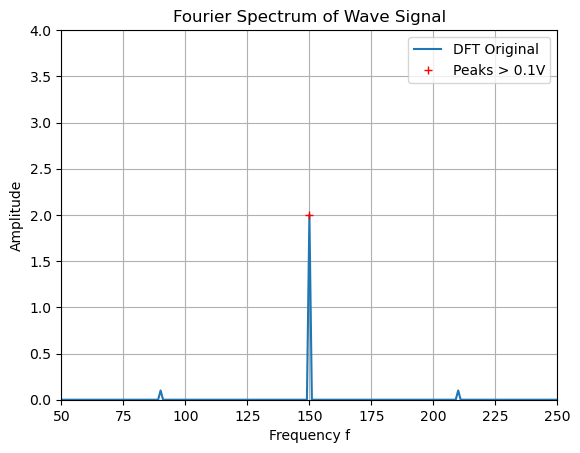

Frequencies of dominant signal is [150.] Hz
Amplitude of dominant signal is [2.] V
Phase offset of dominant signal is [-0.57079633] Rad


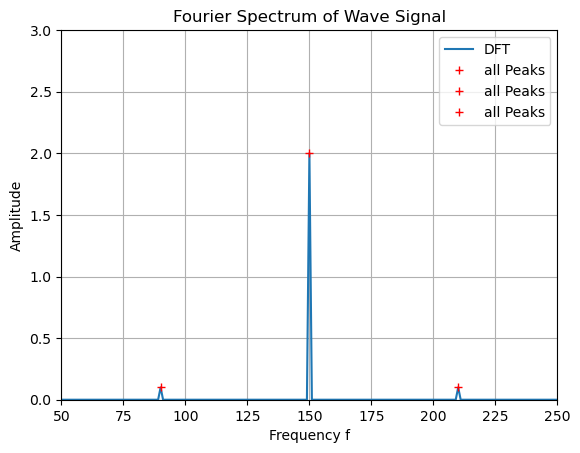

All peak frequencies: [ 90. 210. 150.] Hz
All peak amplitudes: [0.1 0.1 2. ] V
All peak phase offsets: [ 1.         -2.14159265 -0.57079633] Rads


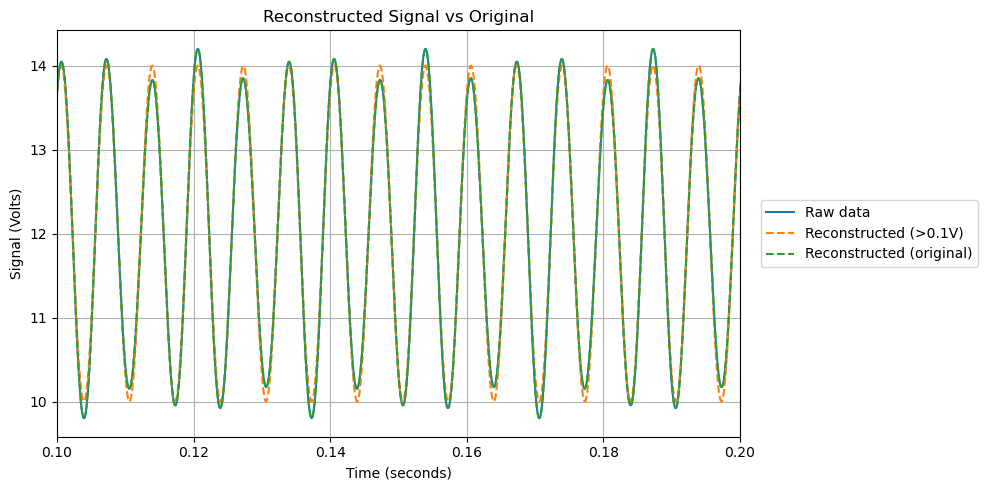

Main signal amplitude X_s = 1.9999999999999987V vs expected 2.0000000000000004V
Main signal frequency f_s = 150.00000000000003V vs expected 150.0V
New signal amplitude delta_X = -0.19999999999999998
New signal + phase offset phi_+ = 0.9999999999999842 vs expected 1.0000000000000102
New signal - phase offset phi_- = -2.1415926535898047 vs expected -2.141592653589807
New signal + frequency f_+ = f_s + 60 = 210.00000000000003Hz vs expected 210.0 Hz
New signal - frequency f_- = f_s - 60 = 90.00000000000003Hz vs expected 90.0 Hz


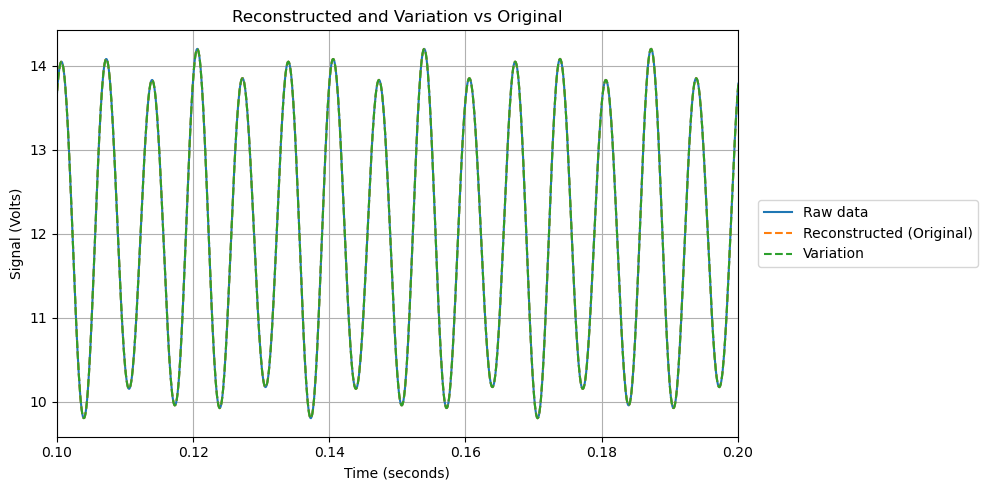

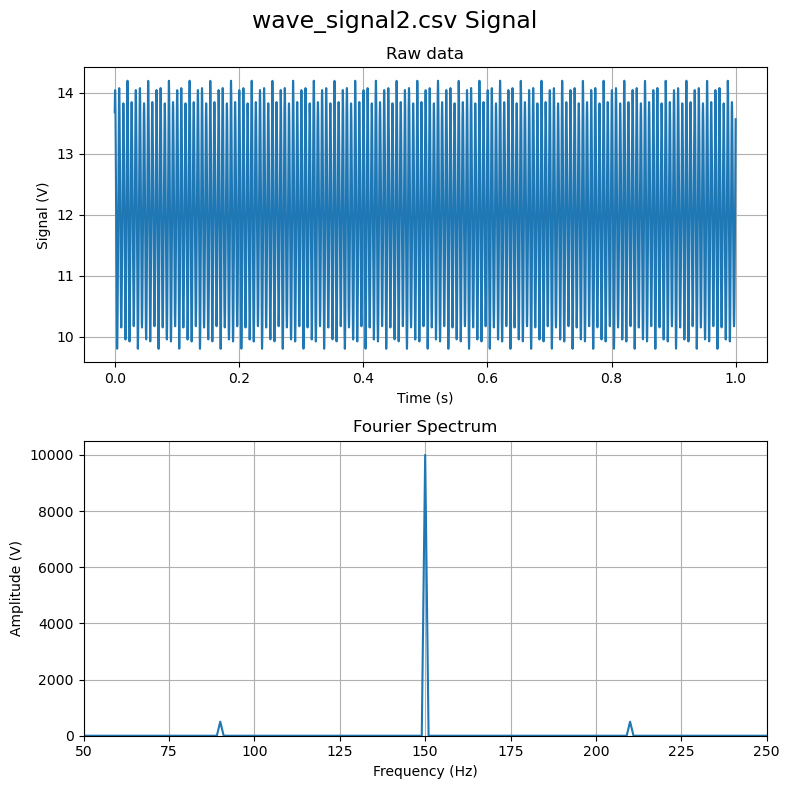

In [341]:
# Question 3: wave_signal.csv Analysis

# Import Libraries
import numpy as np 
import matplotlib.pyplot as plt 
import pandas as pd
import scipy

# Part a): Calculate amplitude, frequency, phase offset 

# Extract the data

data = pd.read_csv('wave_signal.csv', dtype={"time": float, "signal": float})
time = data["time"].copy() # seconds
signal = data["signal"].copy() # volts
dt = time[1] - time[0] # Sampling rate 
N = len(signal) # number of signal points

# Compute the discrete Fourier transform

# Amplitude
signal_fft = scipy.fft.rfft(signal)
amplitude = 2/N * np.abs(signal_fft) 
# x2 because of negative and positive symmetry

# Ignore amplitude values less than 0.1V
amplitude_original = amplitude.copy() # for part c)
amplitude[amplitude < 0.1] = 0 # set to zero so dt stays consistent throughout

# Frequencies
freq = scipy.fft.rfftfreq(len(time), dt)

# Phase offset - get the argument of the complex amplitudes
phase = np.angle(signal_fft)

# Find the maximum frequencies

max_ids, _ = scipy.signal.find_peaks(amplitude, distance= 5)

# Plot the spectrum and peaks to see if they're right
plt.plot(freq, amplitude_original, label = 'DFT Original')
plt.plot(freq[max_ids], amplitude[max_ids],'r+', label = 'Peaks > 0.1V')
plt.xlabel('Frequency f')
plt.ylabel('Amplitude')
plt.title('Fourier Spectrum of Wave Signal')
plt.ylim(0, 4)
plt.legend()
plt.xlim(50, 250)
plt.grid()
plt.show()

# So for the dominant wave:

print(f'Frequencies of dominant signal is {freq[max_ids]} Hz')
print(f'Amplitude of dominant signal is {amplitude[max_ids]} V')
print(f'Phase offset of dominant signal is {phase[max_ids]} Rad')

# Pick out the peaks without filtering

max_ids2, _ = scipy.signal.find_peaks(amplitude_original, distance = 3)

maxes = np.argsort(amplitude_original[max_ids2]) # sort in increasing amplitude
peaks = max_ids2[maxes[-3:]] # indices of the top 3 frequencies

# Plot the spectrum and peaks to see if they're right
plt.plot(freq, amplitude_original, label = 'DFT')
for k in peaks: 
    plt.plot(freq[k], amplitude_original[k],'r+', label = 'all Peaks')
plt.xlabel('Frequency f')
plt.ylabel('Amplitude')
plt.title('Fourier Spectrum of Wave Signal')
plt.legend()
plt.ylim(0, 3)
plt.xlim(50, 250)
plt.grid()
plt.show()

print(f'All peak frequencies: {freq[peaks]} Hz')
print(f'All peak amplitudes: {amplitude_original[peaks]} V')
print(f'All peak phase offsets: {phase[peaks]} Rads')

# Part b): Reconstruct the wave using FFT

# only dominant frequency 
signal_reconstruct = amplitude[max_ids] * np.cos(
    2*np.pi*freq[max_ids]*time + phase[max_ids])
# add in zeroeth frequency term
signal_reconstruct += amplitude[0]/2 # cuz DC term is 1/N instead of 2/N

# all the peaks together
# create reconstruction same size as original signal
signal_reconstruct2 = np.zeros_like(time, dtype=float) 

for k in peaks:
    signal_reconstruct2 += amplitude_original[k] * np.cos(
        2*np.pi*freq[k]*time + phase[k])

# add in zeroeth frequency term
signal_reconstruct2 += amplitude_original[0]/2

plt.figure(figsize = (10,5))
plt.plot(time, signal, label = 'Raw data')
plt.plot(time, signal_reconstruct, '--', label = 'Reconstructed (>0.1V)')
plt.plot(time, signal_reconstruct2, '--', label = 'Reconstructed (original)')
plt.grid()
plt.xlabel('Time (seconds)')
plt.ylabel('Signal (Volts)')
plt.title('Reconstructed Signal vs Original')
plt.xlim(0.1, 0.2) # Zoom in for better visibility
plt.legend(loc="center left", bbox_to_anchor=(1.02, 0.5))
plt.tight_layout()
plt.show()

# Part c): Reconstruct the wave with variation of 60 Hz

# So frequencies
freq2 = scipy.fft.rfftfreq(len(time), dt)[peaks]

# Phase offset - get the argument of the complex amplitudes
phase2 = np.angle(signal_fft[peaks])

def variation(t, X_s, delta_X, f_s, phi_s, delta_phi): 
    """
    Function for curve fitting of the signal
    Inputs: 
    t = time 
    X_s = Main frequency amplitude 
    delta_X = Variation frequency amplitude
    f_s = Main frequency 
    phi_s = Main phase offset 
    delta_phi = Variation phase offset 
    
    Outputs: 
    Value of signal at time t reconstructed from parameters
    """
    return amplitude[0]/2 + X_s * np.cos(
        2*np.pi*f_s*t + phi_s) + delta_X * np.cos(2*np.pi*(60*t) 
                       + delta_phi)*np.cos(2*np.pi*f_s*t + phi_s)

popt, _ = scipy.optimize.curve_fit(
    variation, time, signal, p0 = [amplitude[max_ids[0]], 1, 
                                   freq[max_ids[0]], phase[max_ids[0]], 
                                   np.abs(phase2[-1] - phase2[0])])
X_s,delta_X, f_s, phi_s, delta_phi =  popt[0], popt[1], popt[2], popt[3], popt[4]
# Print the parameters
print(f'Main signal amplitude X_s = {X_s}V vs expected {amplitude_original[peaks[-1]]}V')
print(f'Main signal frequency f_s = {f_s}V vs expected {freq[max_ids[0]]}V')
print(f'New signal amplitude delta_X = {delta_X}')
print(f'New signal + phase offset phi_+ = {phi_s + delta_phi} vs expected {phase2[0]}')
print(f'New signal - phase offset phi_- = {phi_s - delta_phi} vs expected {phase2[1]}')
print(f'New signal + frequency f_+ = f_s + 60 = {f_s + 60}Hz vs expected {freq2[1]} Hz')
print(f'New signal - frequency f_- = f_s - 60 = {f_s - 60}Hz vs expected {freq2[0]} Hz')

# Plot them to see if it's the same thing

plt.figure(figsize = (10,5))
plt.plot(time, signal, label = 'Raw data')
plt.plot(time, signal_reconstruct2, '--', label = 'Reconstructed (Original)')
plt.plot(time, variation(time, *popt), '--', label = 'Variation')
plt.grid()
plt.xlabel('Time (seconds)')
plt.ylabel('Signal (Volts)')
plt.title('Reconstructed and Variation vs Original')
plt.xlim(0.1, 0.2) # limited for better visibility
plt.legend(loc="center left", bbox_to_anchor=(1.02, 0.5))
plt.tight_layout()
plt.show()

# Part e): DFT for wave_signal2.csv

# Extract the data

data2 = pd.read_csv('wave_signal2.csv', dtype={"time": float, "signal": float})
time2 = data["time"] # seconds
signal2 = data["signal"] # volts
dt2 = time[1] - time[0] # Sampling rate 

# Compute the discrete Fourier transform

# Amplitude
signal2_fft = scipy.fft.rfft(signal2)
amplitude2 = np.abs(signal2_fft)
# Frequencies
freq2 = scipy.fft.rfftfreq(len(time2), dt2)

# Phase offset - get the argument of the complex amplitudes
phase2 = np.angle(signal2_fft)

# Plot the data and Fourier transform 
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 8), sharex=False)
fig.suptitle('wave_signal2.csv Signal', fontsize=17)

ax1.plot(time2, signal2)
ax1.set_title("Raw data")
ax1.set_xlabel("Time (s)")
ax1.set_ylabel("Signal (V)")
ax1.grid(True)

ax2.plot(freq2, amplitude2)
ax2.set_title("Fourier Spectrum")
ax2.set_xlabel("Frequency (Hz)")
ax2.set_ylabel("Amplitude (V)")
ax2.grid(True)
ax2.set_xlim(50, 250)
ax2.set_ylim(0,10500)

plt.tight_layout()
plt.show()